In [3]:
import boto3 
import duckdb
import pandas as pd 
import matplotlib.pyplot as plt 
from pathlib import Path 

if not Path("events.parquet").exists(): 
    s3 = boto3.client("s3")
    s3.download_file(
        "dsan6000-data",
        "acled_events.parquet",
        "events.parquet"
    )

#connecting to duckdb 
events_con = duckdb.connect() 

#checking dataset
events_con.sql("""
    SELECT
        MIN(TRY_CAST(event_date AS DATE)) AS first_date,
        MAX(TRY_CAST(event_date AS DATE)) AS last_date,
        COUNT(*) AS total_events
    FROM 'events.parquet'
""").show()

┌────────────┬────────────┬──────────────┐
│ first_date │ last_date  │ total_events │
│    date    │    date    │    int64     │
├────────────┼────────────┼──────────────┤
│ 1997-01-01 │ 2025-09-26 │      2781033 │
└────────────┴────────────┴──────────────┘



,year,event_count
0,1997,3141
1,1998,4421
2,1999,4758
3,2000,4116
4,2001,3557
5,2002,4209
6,2003,3655
7,2004,3098
8,2005,2869
9,2006,2710


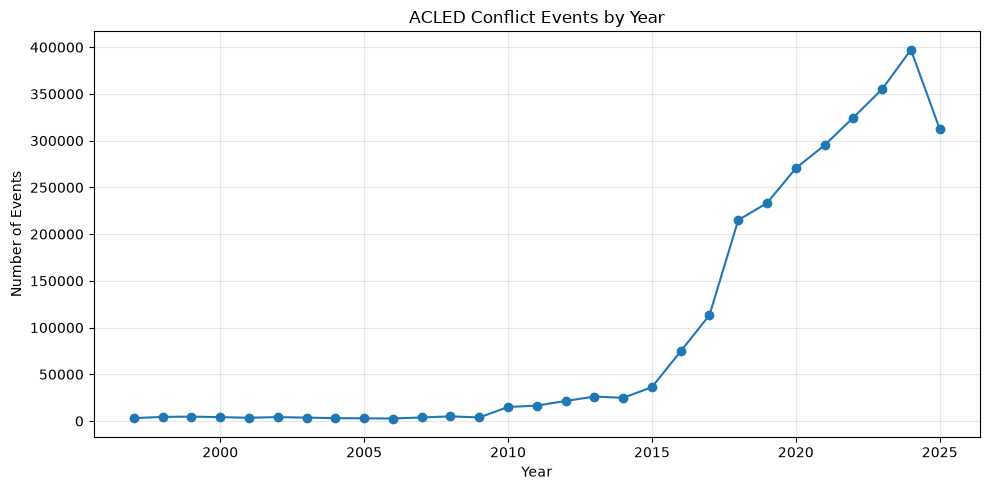

In [4]:
#EVENTS BY YEAR 

#counting conflict events by year 
yearly_df = events_con.sql("""
    SELECT
        year,
        COUNT(*) AS event_count
    FROM 'events.parquet'
    WHERE year IS NOT NULL
    GROUP BY year
    ORDER BY year
""").df()

display(yearly_df)

plt.figure(figsize=(10,5))
plt.plot(yearly_df["year"], yearly_df["event_count"], marker="o")
plt.title("ACLED Conflict Events by Year")
plt.xlabel("Year")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,month,event_count
333,2024-10-01,38238
334,2024-11-01,35017
335,2024-12-01,31502
336,2025-01-01,33203
337,2025-02-01,32508
338,2025-03-01,37938
339,2025-04-01,35662
340,2025-05-01,36570
341,2025-06-01,35817
342,2025-07-01,35409


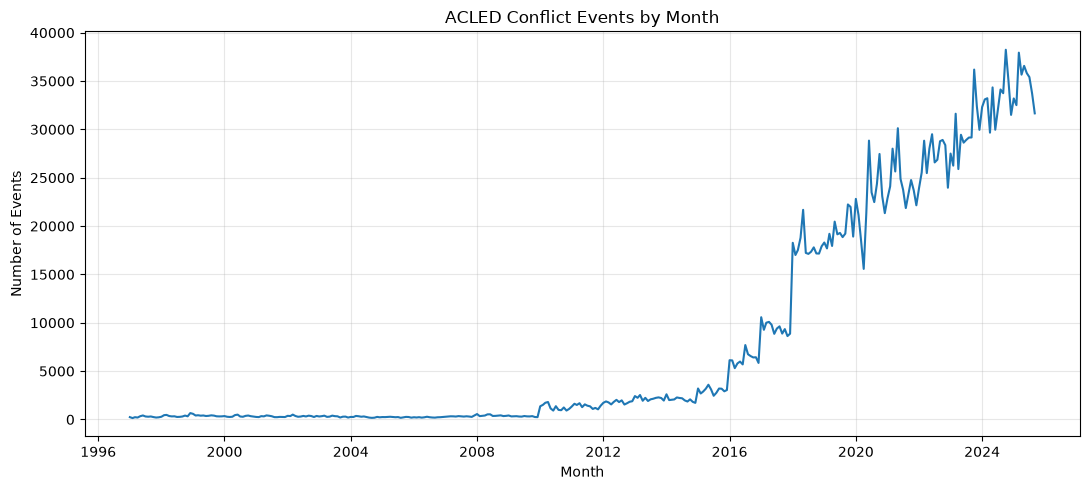

In [ ]:
#EVENTS BY MONTH 

#counting conflict events by month
monthly_df = events_con.sql("""
    SELECT
        DATE_TRUNC('month', TRY_CAST(event_date AS DATE)) AS month,
        COUNT(*) AS event_count
    FROM 'events.parquet'
    WHERE TRY_CAST(event_date AS DATE) IS NOT NULL
    GROUP BY month
    ORDER BY month
""").df()

monthly_df["month"] = pd.to_datetime(monthly_df["month"])

display(monthly_df.tail(12))

plt.figure(figsize=(11,5))
plt.plot(monthly_df["month"], monthly_df["event_count"])
plt.title("ACLED Conflict Events by Month")
plt.xlabel("Month")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

month_num
1     1.035668
2     0.969925
3     1.069874
4     0.991637
5     1.059365
6     1.072403
7     1.004296
8     0.939881
9     0.947834
10    1.016070
11    0.935185
12    0.957862
Name: relative_count, dtype: float64

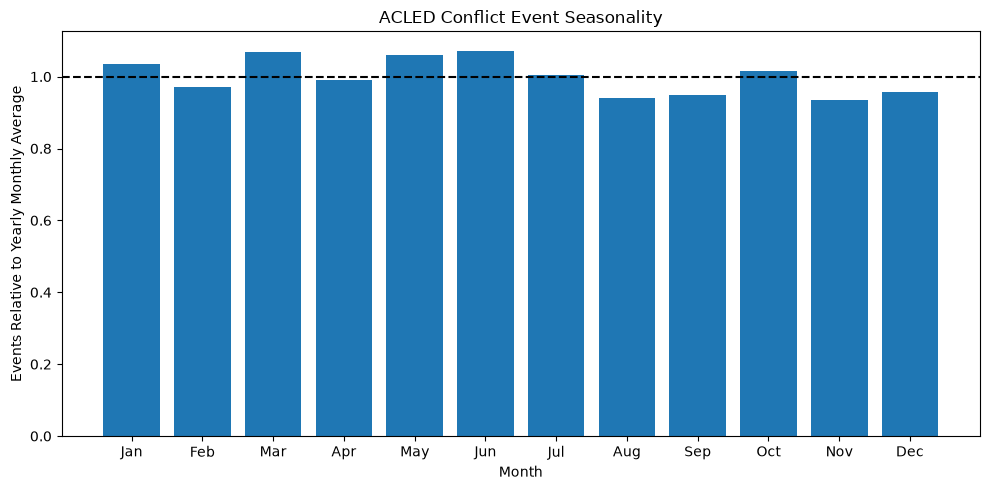

In [6]:
#SEASONALITY 

#look for seasonal patterns in conflict events 
season_df = monthly_df.copy()
season_df["year"] = season_df["month"].dt.year
season_df["month_num"] = season_df["month"].dt.month

#only including years with all 12 months 
complete_years = (
    season_df.groupby("year")["month_num"]
    .nunique()
)
complete_years = complete_years[complete_years == 12].index
season_df = season_df[season_df["year"].isin(complete_years)].copy()

#comparing each month with its year's monthly average
season_df["relative_count"] = (
    season_df["event_count"] / season_df.groupby("year")["event_count"].transform("mean")

)

seasonality = (
    season_df.groupby("month_num")["relative_count"]
    .mean()
)

display(seasonality)

plt.figure(figsize=(10,5))
plt.bar(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    seasonality.reindex(range(1, 13))
)

plt.axhline(1, color="black", linestyle="--")
plt.title("ACLED Conflict Event Seasonality")
plt.xlabel("Month")
plt.ylabel("Events Relative to Yearly Monthly Average")
plt.tight_layout()
plt.show()